# Позиционные эмбеддинги, или Почему 3 + 5 не всегда 8

Ноутбук к моей статье на Хабре. Здесь все вычисления, которые я делала, пока разбиралась с разделом 2.8 книги Себастьяна Рашки «Строим LLM с нуля».

Что внутри:

1. Почему attention без позиций не видит порядок слов (dog bites man vs man bites dog).
2. Код из книги: как складываются эмбеддинги слов и позиций.
3. Главный эксперимент: можно ли достать слово и позицию обратно из их суммы.
4. Почему это работает: случайные векторы в многомерном пространстве почти перпендикулярны.
5. Как attention сам «раскрывает скобки» и делит сигнал на четыре части.
6. Почему складывать — почти то же самое, что склеивать.

Нужны только `numpy` и `matplotlib`. PyTorch опционален, он нужен для одной ячейки с кодом из книги. Все графики сохраняются в папку `figures/`.

In [11]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

TOKEN_COLOR = "#2a6fdb"   # всё, что про слова, — синее
POS_COLOR = "#e8643a"     # всё, что про позиции, — оранжевое
GREY = "#9a9a9a"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

## 1. Attention без позиций не видит порядок

Соберём самый простой self-attention из одной головы: матрицы `W_q`, `W_k`, `W_v`, softmax и взвешенная сумма. Матрицы и эмбеддинги случайные, нам важна только механика.

Подадим две фразы: `dog bites man` и `man bites dog`. Посмотрим, что attention выдаст для слова `bites`.

In [12]:
d = 16
vocab = {"dog": 0, "bites": 1, "man": 2}
tok_emb = rng.standard_normal((len(vocab), d))
pos_emb = rng.standard_normal((3, d))            # по вектору на каждое из трёх мест
W_q, W_k, W_v = (rng.standard_normal((d, d)) / np.sqrt(d) for _ in range(3))


def softmax(x):
    e = np.exp(x - x.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def self_attention(x):
    q, k, v = x @ W_q, x @ W_k, x @ W_v
    weights = softmax(q @ k.T / np.sqrt(d))
    return weights @ v


def embed(sentence, use_positions):
    x = tok_emb[[vocab[w] for w in sentence.split()]]
    if use_positions:
        x = x + pos_emb
    return x


a, b = "dog bites man", "man bites dog"
for use_pos in (False, True):
    out_a = self_attention(embed(a, use_pos))[1]   # bites стоит на месте 1 в обеих фразах
    out_b = self_attention(embed(b, use_pos))[1]
    label = "с позициями " if use_pos else "без позиций"
    print(f"{label}: выход для 'bites' одинаковый? {np.allclose(out_a, out_b)}  "
          f"(разница {np.abs(out_a - out_b).max():.4f})")

без позиций: выход для 'bites' одинаковый? True  (разница 0.0000)
с позициями : выход для 'bites' одинаковый? False  (разница 1.2562)


Без позиций выход для `bites` совпадает до последнего знака. Для attention фраза — это мешок векторов, и от перестановки слагаемых сумма не меняется. Стоило прибавить позиции — и выходы разошлись: теперь модель может понять, кто кого укусил.

## 2. Как это сделано в книге

Код из раздела 2.8 почти без изменений. Для него нужен PyTorch. Если его нет, ячейка просто пропустится, на остальной ноутбук это не влияет.

In [13]:
try:
    import torch
except ImportError:
    torch = None
    print("PyTorch не установлен — пропускаю эту ячейку. Установить: pip install torch")

if torch is not None:
    torch.manual_seed(123)
    vocab_size, output_dim, context_length, batch_size = 50257, 256, 4, 8

    token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
    pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)

    # вместо настоящего текста — случайные id токенов той же формы, что в книге
    inputs = torch.randint(0, vocab_size, (batch_size, context_length))

    token_embeddings = token_embedding_layer(inputs)
    pos_embeddings = pos_embedding_layer(torch.arange(context_length))
    input_embeddings = token_embeddings + pos_embeddings   # broadcasting по батчу

    print("token_embeddings:", tuple(token_embeddings.shape))
    print("pos_embeddings:  ", tuple(pos_embeddings.shape))
    print("input_embeddings:", tuple(input_embeddings.shape))

token_embeddings: (8, 4, 256)
pos_embeddings:   (4, 256)
input_embeddings: (8, 4, 256)


Обратите внимание на форму `pos_embeddings`: `[4, 256]`, а не `[8, 4, 256]`. Позиция не зависит от строки батча, и PyTorch сам растягивает её на все восемь строк.

## 3. Главный эксперимент: можно ли достать слово из суммы

Берём размеры как у GPT-2: словарь на 50 257 токенов и 1 024 позиции. Обе таблицы заполняем случайными числами, как в главе 2, без обучения.

Дальше много раз повторяем одно и то же:

1. берём случайное слово и случайную позицию;
2. складываем их векторы;
3. ищем по сумме ближайшее слово из словаря и ближайшую позицию (по скалярному произведению);
4. проверяем, совпало ли с тем, что складывали.

И так для разных размерностей эмбеддинга: от 4 до 256.

In [14]:
VOCAB_SIZE, CONTEXT_LEN = 50257, 1024
DIMS = [4, 8, 16, 32, 48, 64, 96, 128, 256]
N_TRIALS = 300


def recovery_accuracy(d, ids, ps, r):
    tok = r.standard_normal((VOCAB_SIZE, d)).astype(np.float32)   # таблица слов
    pos = r.standard_normal((CONTEXT_LEN, d)).astype(np.float32)  # таблица позиций
    x = tok[ids] + pos[ps]                                        # то, что идёт на вход модели
    tok_acc = ((x @ tok.T).argmax(axis=1) == ids).mean()          # ближайшее слово
    pos_acc = ((x @ pos.T).argmax(axis=1) == ps).mean()           # ближайшая позиция
    return tok_acc, pos_acc


exp_rng = np.random.default_rng(1)                 # тот же seed, что в статье
ids = exp_rng.integers(0, VOCAB_SIZE, N_TRIALS)    # случайные слова
ps = exp_rng.integers(0, CONTEXT_LEN, N_TRIALS)    # случайные позиции
results = {d: recovery_accuracy(d, ids, ps, exp_rng) for d in DIMS}
print(f"{'d':>5} | {'слово':>6} | {'позиция':>7}")
for d, (t, p) in results.items():
    print(f"{d:>5} | {t:>6.0%} | {p:>7.0%}")

    d |  слово | позиция
    4 |     0% |      1%
    8 |     1% |      8%
   16 |     4% |     29%
   32 |    34% |     79%
   48 |    79% |     94%
   64 |    95% |    100%
   96 |   100% |    100%
  128 |   100% |    100%
  256 |   100% |    100%


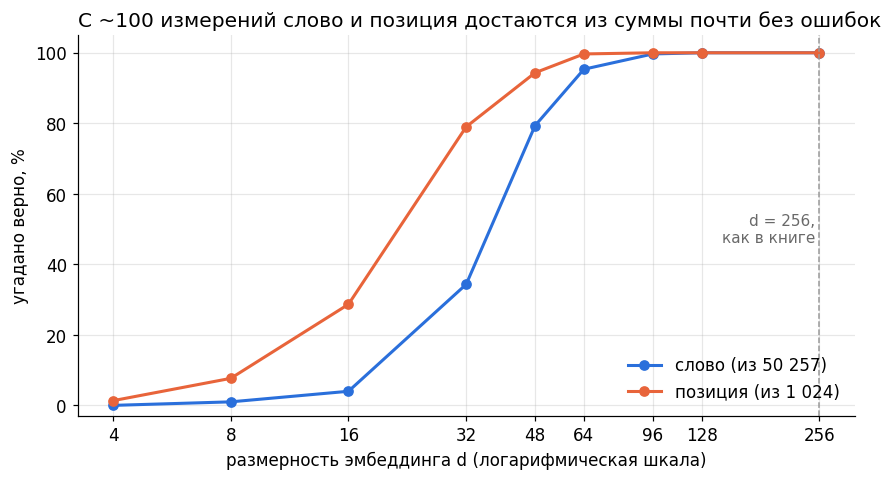

In [15]:
tok_acc = [results[d][0] * 100 for d in DIMS]
pos_acc = [results[d][1] * 100 for d in DIMS]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(DIMS, tok_acc, "o-", color=TOKEN_COLOR, lw=2, label="слово (из 50 257)")
ax.plot(DIMS, pos_acc, "o-", color=POS_COLOR, lw=2, label="позиция (из 1 024)")
ax.axvline(256, color=GREY, ls="--", lw=1)
ax.text(250, 50, "d = 256,\nкак в книге", ha="right", va="center", color="dimgray", fontsize=10)
ax.set_xscale("log", base=2)
ax.set_xticks(DIMS, [str(d) for d in DIMS])
ax.set_ylim(-3, 105)
ax.set_xlabel("размерность эмбеддинга d (логарифмическая шкала)")
ax.set_ylabel("угадано верно, %")
ax.set_title("С ~100 измерений слово и позиция достаются из суммы почти без ошибок", loc="left")
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "recovery_by_dim.png", dpi=150)
plt.show()

При 4–16 измерениях сумма и правда каша, тут «школьная» интуиция про 3 + 5 = 8 права. А примерно со 100 измерений и слово, и позиция находятся практически всегда. И это на случайных векторах, без всякого обучения.

Позиция находится легче слова, потому что угадать один вариант из 1 024 проще, чем из 50 257.

Проверим d = 256 на выборке побольше, чтобы убедиться, что это не везение.

In [16]:
big_rng = np.random.default_rng(7)
big_ids = big_rng.integers(0, VOCAB_SIZE, 2000)
big_ps = big_rng.integers(0, CONTEXT_LEN, 2000)
t, p = recovery_accuracy(256, big_ids, big_ps, big_rng)
print(f"d = 256, 2000 пар: слово угадано в {t:.2%} случаев, позиция — в {p:.2%}")

d = 256, 2000 пар: слово угадано в 100.00% случаев, позиция — в 100.00%


## 4. Почему так: в многомерном пространстве всё почти перпендикулярно

Посмотрим, как распределён косинус угла между двумя случайными векторами. На плоскости (d = 2) векторы часто смотрят в одну сторону. Чем больше измерений, тем плотнее косинус прижимается к нулю, то есть векторы почти перпендикулярны.

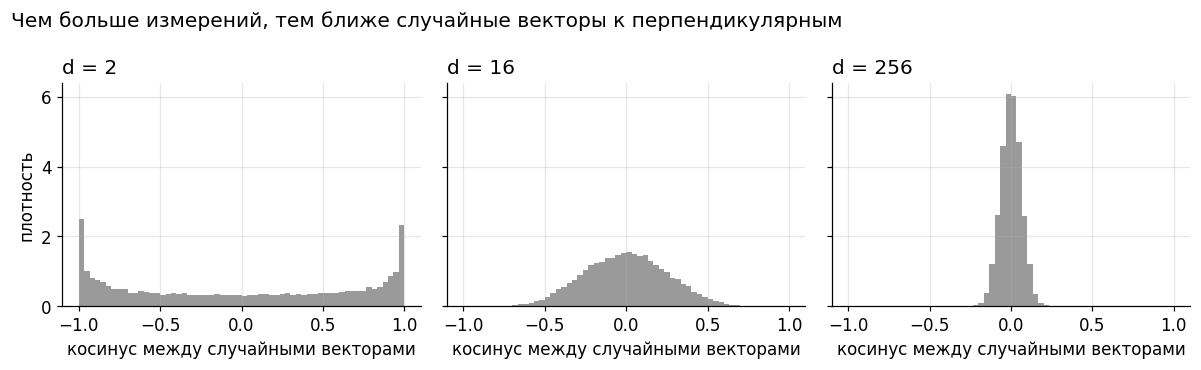

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, d in zip(axes, [2, 16, 256]):
    u = rng.standard_normal((20000, d))
    v = rng.standard_normal((20000, d))
    cos = (u * v).sum(1) / np.linalg.norm(u, axis=1) / np.linalg.norm(v, axis=1)
    ax.hist(cos, bins=60, range=(-1, 1), color=GREY, density=True)
    ax.set_title(f"d = {d}", loc="left")
    ax.set_xlabel("косинус между случайными векторами")
axes[0].set_ylabel("плотность")
fig.suptitle("Чем больше измерений, тем ближе случайные векторы к перпендикулярным", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG / "random_cosines.png", dpi=150)
plt.show()

А теперь главное для нашего вопроса: насколько сумма «слово + позиция» похожа на своё слово и насколько на случайное чужое. Берём d = 256, как в книге.

сумма ↔ своё слово:  средний косинус 0.71
сумма ↔ чужое слово: средний |косинус| 0.05


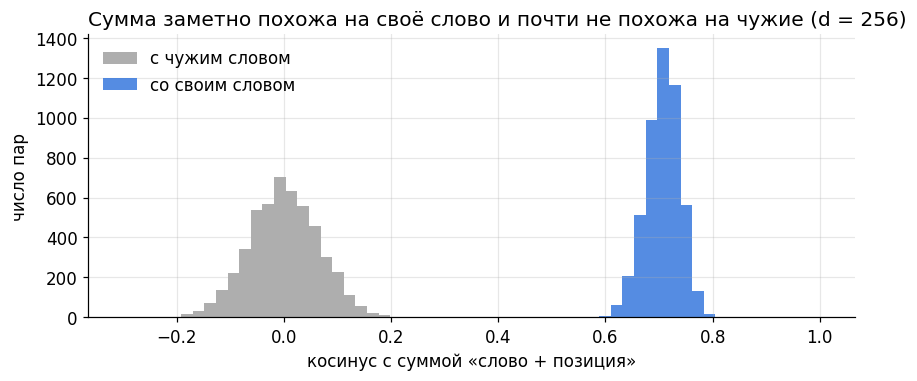

In [18]:
d, n = 256, 5000
tok = rng.standard_normal((n, d))
pos = rng.standard_normal((n, d))
other = rng.standard_normal((n, d))
x = tok + pos


def cosine(a, b):
    return (a * b).sum(1) / np.linalg.norm(a, axis=1) / np.linalg.norm(b, axis=1)


own, foreign = cosine(x, tok), cosine(x, other)
print(f"сумма ↔ своё слово:  средний косинус {own.mean():.2f}")
print(f"сумма ↔ чужое слово: средний |косинус| {np.abs(foreign).mean():.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(foreign, bins=60, range=(-0.3, 1), color=GREY, alpha=0.8, label="с чужим словом")
ax.hist(own, bins=60, range=(-0.3, 1), color=TOKEN_COLOR, alpha=0.8, label="со своим словом")
ax.set_xlabel("косинус с суммой «слово + позиция»")
ax.set_ylabel("число пар")
ax.set_title("Сумма заметно похожа на своё слово и почти не похожа на чужие (d = 256)", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "own_vs_foreign_cosine.png", dpi=150)
plt.show()

Своё слово: около 0,71. Чужое: около 0,05. Смысл слова в сумме приглушён, но два распределения даже не пересекаются. Как две ноты в аккорде: звучат одновременно, а ухо слышит обе.

## 5. Attention сам раскрывает скобки

Модели не нужно явно разбирать сумму обратно. Запрос и ключ получаются умножением на матрицу, а матрица распределяется по сумме:

$$q_i = W_q(t_i + p_i) = W_q t_i + W_q p_i$$

Значит, скалярное произведение `q_i · k_j` распадается на четыре слагаемых: слово–слово, слово–место, место–слово и место–место. Проверим это численно.

In [19]:
d = 256
W_q = rng.standard_normal((d, d)) / np.sqrt(d)
W_k = rng.standard_normal((d, d)) / np.sqrt(d)
t_i, t_j, p_i, p_j = rng.standard_normal((4, d))

full = (W_q @ (t_i + p_i)) @ (W_k @ (t_j + p_j))
terms = {
    "слово–слово":  (W_q @ t_i) @ (W_k @ t_j),
    "слово–место":  (W_q @ t_i) @ (W_k @ p_j),
    "место–слово":  (W_q @ p_i) @ (W_k @ t_j),
    "место–место":  (W_q @ p_i) @ (W_k @ p_j),
}
for name, value in terms.items():
    print(f"{name:<12} {value:>9.3f}")
print(f"{'сумма':<12} {sum(terms.values()):>9.3f}")
print(f"{'q · k':<12} {full:>9.3f}")
print("совпадает:", np.isclose(full, sum(terms.values())))

слово–слово    -17.843
слово–место      7.229
место–слово    -23.486
место–место      6.386
сумма          -27.713
q · k          -27.713
совпадает: True


Совпадает. Матрицы обучаемые, поэтому модель сама решает, какое из четырёх слагаемых важнее для каждой attention-головы. Одна голова может почти не замечать позицию, другая — почти не замечать смысл.

## 6. Складывать или склеивать?

Склейка `[t; p]` удваивает размерность. Но за ней всё равно идёт линейный слой, а он делает ровно то же, что сложение двух преобразованных векторов:

$$W\,[t;\,p] = W_1 t + W_2 p$$

Проверим.

In [20]:
d, d_out = 256, 64
t, p = rng.standard_normal((2, d))
W = rng.standard_normal((d_out, 2 * d))
W1, W2 = W[:, :d], W[:, d:]

concat_then_linear = W @ np.concatenate([t, p])
sum_of_projections = W1 @ t + W2 @ p
print("одинаково:", np.allclose(concat_then_linear, sum_of_projections))

одинаково: True


Раз эмбеддинги и так обучаемые, модель может выучить `W1` и `W2` сама. Сложение дешевле и почти ничего не теряет.

## Итог

1. Позиция нужна, потому что attention сам по себе порядок слов не видит.
2. В 256 измерениях сумма векторов — не каша: по ней однозначно находятся и слово, и позиция.
3. Модели не нужно явно разбирать сумму: линейные слои attention раскрывают скобки сами.

Если нашли ошибку или есть идея, что ещё проверить, — пишите в issues или в комментариях к статье на Хабре.